# Results walkthrough

Reads the committed result tables in `results/` (produced on Linux by the CI run) and shows them next to each other. Nothing is recomputed here; to regenerate the results run `python -m stroke_imbalance.run --config configs/paper.yaml`.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from stroke_imbalance.cv import format_mean_std
from stroke_imbalance.evaluate import format_comparison

RESULTS = Path('..') / 'results'
paper = RESULTS / 'paper'

## Table III: training-set class counts per resampling regime

In [2]:
pd.read_csv(paper / 'table3_class_counts.csv')

,Regime,No stroke,Stroke,Total
0,Original,3889,199,4088
1,SMOTE,3889,3889,7778
2,SMOTE-ENN,3148,3618,6766


## Table IV: hold-out test set (1,022 patients, 50 strokes)

With 50 positive patients, one patient is 2 points of recall.

In [3]:
table4 = pd.read_csv(paper / 'table4.csv')
table4.round(3)

,Model,Resampling,Accuracy,Precision,Recall,F1,PR_AUC
0,LR,Original,0.951,0.000,0.00,0.000,0.257
1,LR,SMOTE,0.757,0.141,0.78,0.239,0.266
2,LR,SMOTE-ENN,0.717,0.128,0.82,0.221,0.259
3,SVM,Original,0.951,0.000,0.00,0.000,0.096
4,SVM,SMOTE,0.754,0.135,0.74,0.228,0.212
5,SVM,SMOTE-ENN,0.715,0.122,0.78,0.211,0.207
6,XGB,Original,0.951,0.500,0.04,0.074,0.207
7,XGB,SMOTE,0.889,0.221,0.50,0.307,0.199
8,XGB,SMOTE-ENN,0.819,0.164,0.66,0.263,0.215


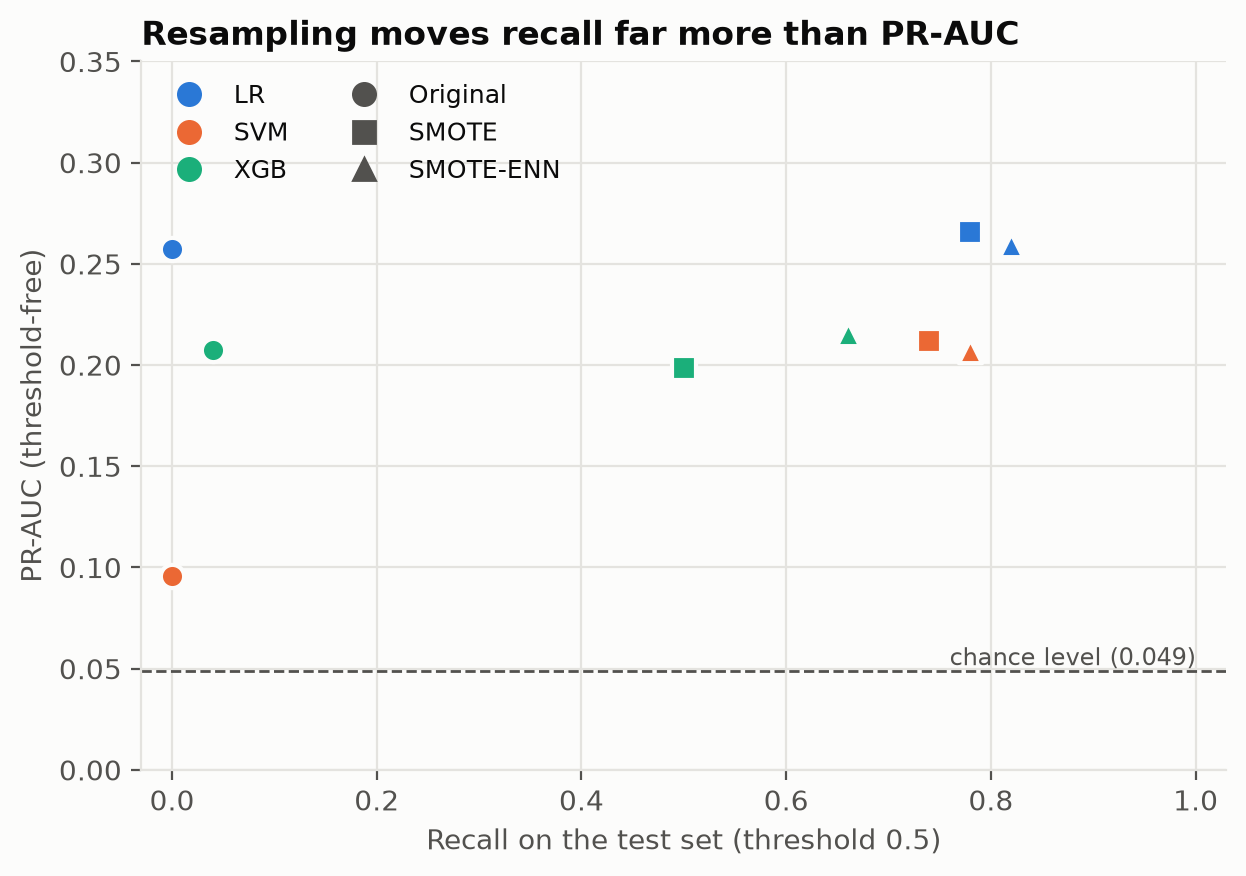

In [4]:
display(Image(paper / 'figures' / 'pr_auc_vs_recall.png'))

## Table V: 5x5 repeated stratified cross-validation (reconstruction)

In [5]:
format_mean_std(pd.read_csv(paper / 'table5_cv.csv'))

,Model,Resampling,PR_AUC,Recall,F1
0,LR,SMOTE,0.188 ± 0.034,0.762 ± 0.055,0.224 ± 0.018
1,LR,SMOTE-ENN,0.188 ± 0.035,0.841 ± 0.044,0.216 ± 0.014
2,SVM,SMOTE,0.132 ± 0.020,0.612 ± 0.066,0.189 ± 0.020
3,SVM,SMOTE-ENN,0.132 ± 0.020,0.704 ± 0.058,0.194 ± 0.017
4,XGB,SMOTE,0.154 ± 0.032,0.272 ± 0.064,0.187 ± 0.037
5,XGB,SMOTE-ENN,0.155 ± 0.035,0.521 ± 0.078,0.221 ± 0.030


## Fig 5: SHAP feature impact (reconstruction)

,Feature,Mean_abs_SHAP
0,age,2.198
1,work_type,0.469
2,bmi,0.388
3,smoking_status,0.313
4,avg_glucose_level,0.197
5,gender,0.166
6,Residence_type,0.107
7,ever_married,0.070
8,hypertension,0.054
9,heart_disease,0.022


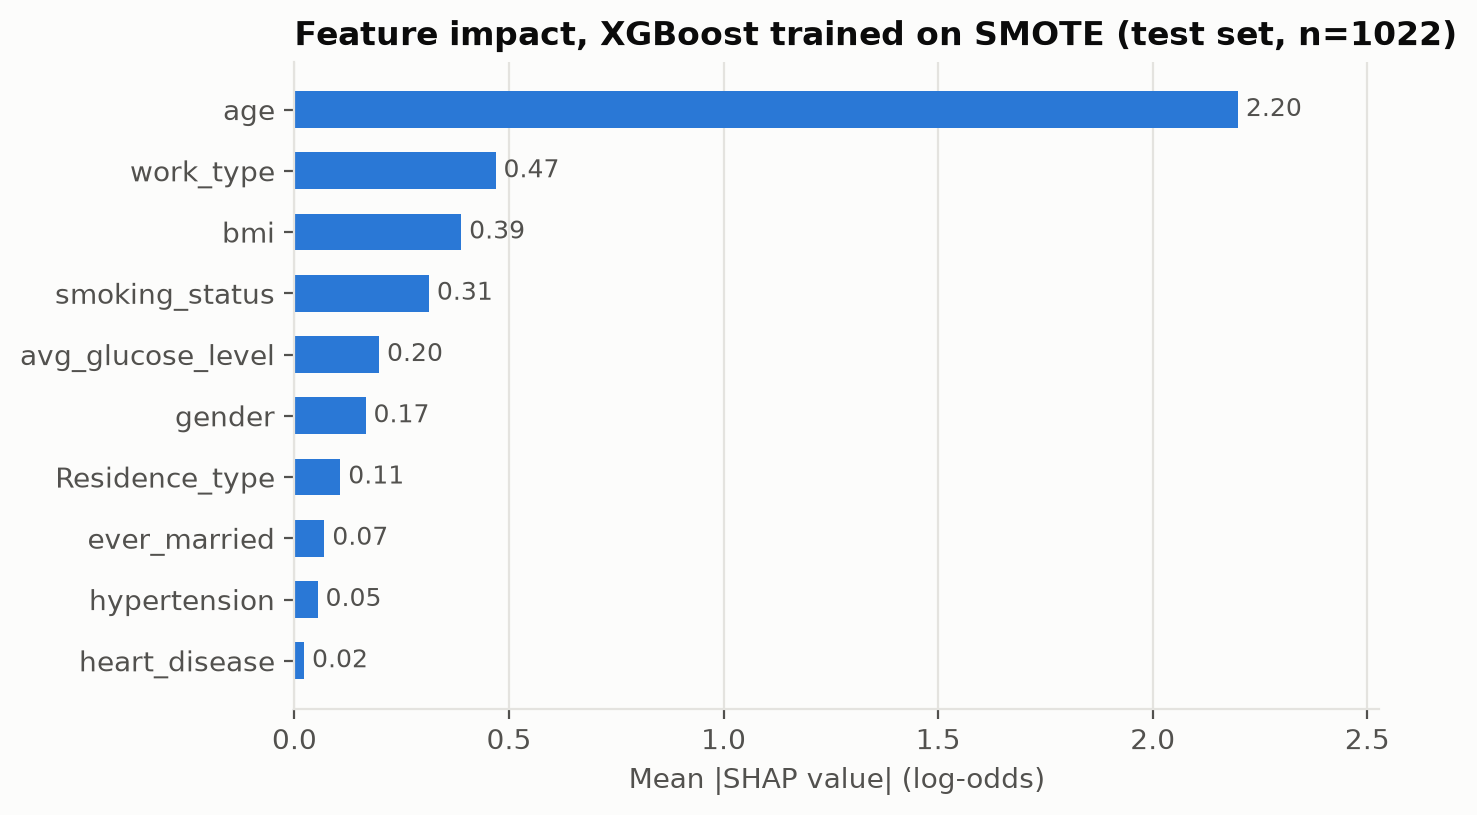

In [6]:
display(pd.read_csv(paper / 'shap_xgb_smote.csv').round(3))
display(Image(paper / 'figures' / 'fig5_shap_xgb_smote.png'))

## XGBoost gain importance and LR coefficients (reconstruction)

In [7]:
display(pd.read_csv(paper / 'xgb_gain_smote.csv').round(3))
display(pd.read_csv(paper / 'lr_coefficients_smote.csv').round(3))

,Feature,Gain
0,age,0.251
1,work_type,0.181
2,smoking_status,0.110
3,ever_married,0.103
4,gender,0.078
5,heart_disease,0.077
6,hypertension,0.071
7,bmi,0.051
8,avg_glucose_level,0.042
9,Residence_type,0.037


,Feature,Coefficient,Sign
0,age,7.254,+
1,avg_glucose_level,1.039,+
2,hypertension,0.485,+
3,heart_disease,0.293,+
4,ever_married,0.220,+
5,gender,0.072,+
6,smoking_status,0.033,+
7,bmi,-0.106,-
8,Residence_type,-0.170,-
9,work_type,-0.334,-


## Fig 6: calibration (reconstruction)

,Model,Brier
0,LR,0.164
1,SVM,0.145
2,XGB,0.080


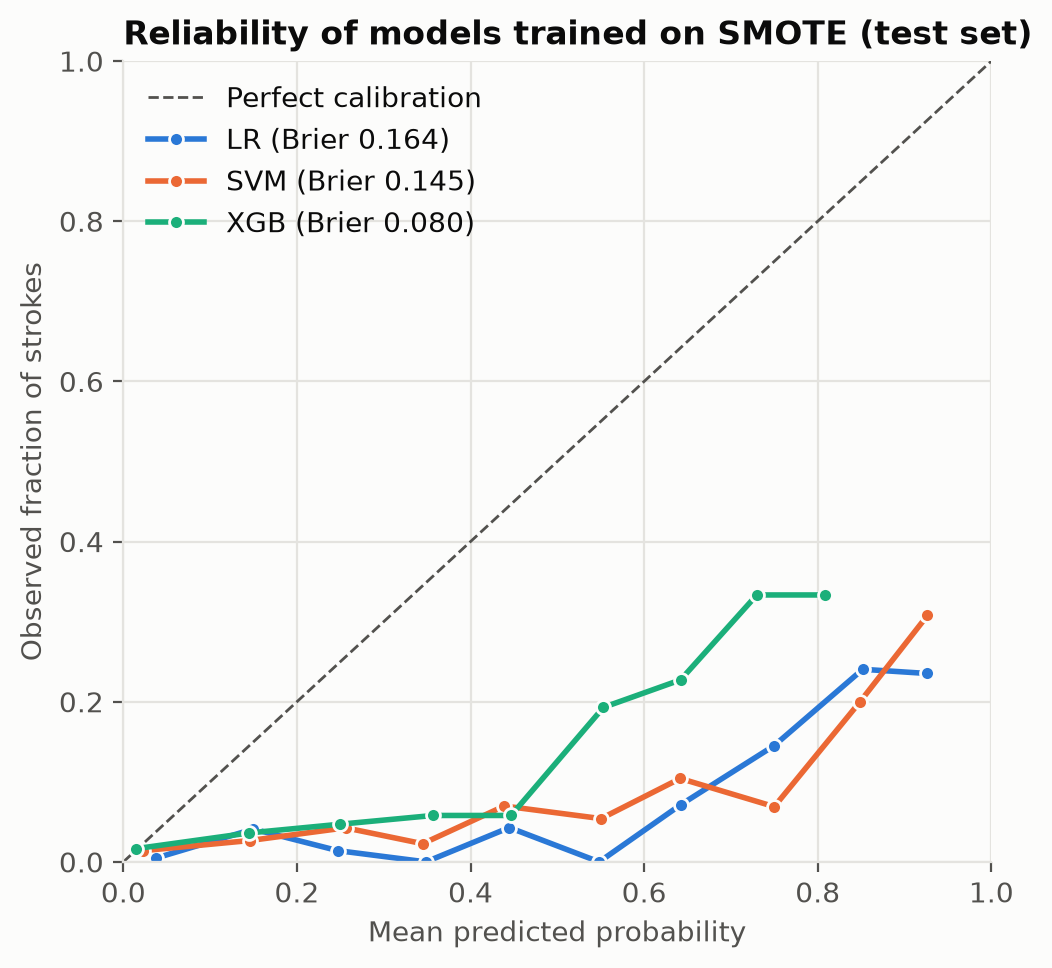

In [8]:
display(pd.read_csv(paper / 'brier_smote.csv').round(3))
display(Image(paper / 'figures' / 'fig6_reliability_smote.png'))

## Corrected profile vs paper profile

BMI imputed with the training-set mean instead of the full-data mean.

In [9]:
comparison = pd.read_csv(RESULTS / 'corrected' / 'table4_vs_paper.csv')
format_comparison(comparison, other='corrected')

,Model,Resampling,Accuracy,Precision,Recall,F1,PR_AUC
0,LR,Original,0.9511 (+0.0000),0.0000 (+0.0000),0.0000 (+0.0000),0.0000 (+0.0000),0.2571 (+0.0000)
1,LR,SMOTE,0.7573 (+0.0000),0.1413 (+0.0000),0.7800 (+0.0000),0.2393 (+0.0000),0.2659 (+0.0001)
2,LR,SMOTE-ENN,0.7182 (+0.0010),0.1281 (+0.0004),0.8200 (+0.0000),0.2216 (+0.0006),0.2590 (-0.0004)
3,SVM,Original,0.9511 (+0.0000),0.0000 (+0.0000),0.0000 (+0.0000),0.0000 (+0.0000),0.0963 (+0.0005)
4,SVM,SMOTE,0.7544 (+0.0000),0.1345 (+0.0000),0.7400 (+0.0000),0.2277 (+0.0000),0.2120 (-0.0000)
5,SVM,SMOTE-ENN,0.7162 (+0.0010),0.1226 (+0.0004),0.7800 (+0.0000),0.2120 (+0.0006),0.2069 (-0.0002)
6,XGB,Original,0.9511 (+0.0000),0.5000 (+0.0000),0.0600 (+0.0200),0.1071 (+0.0331),0.2098 (+0.0025)
7,XGB,SMOTE,0.8904 (+0.0010),0.2182 (-0.0031),0.4800 (-0.0200),0.3000 (-0.0067),0.1974 (-0.0014)
8,XGB,SMOTE-ENN,0.8141 (-0.0049),0.1500 (-0.0142),0.6000 (-0.0600),0.2400 (-0.0229),0.2029 (-0.0122)
